In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# 1. The Setup & Loading Data

In [2]:
# df = pd.read_csv("C:\pp\ml--2026\project\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# df = kagglehub.dataset_download("blastchar/telco-customer-churn")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.shape

(7043, 21)

In [5]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [6]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [7]:
df.describe() 

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


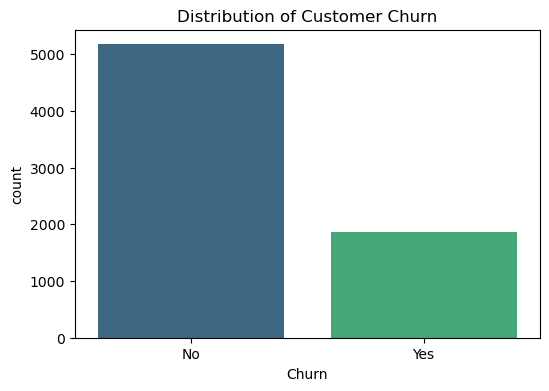

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='viridis')
plt.title('Distribution of Customer Churn')
plt.show()

# Check the percentage
print(df['Churn'].value_counts(normalize=True) * 100)

This dataset contains customer retention data from a telecommunications provider, comprising 7,043 unique customer records across 21 variables. It includes demographic details (gender, partner status), account information (tenure, contract type, payment method), and subscribed services (internet, security, streaming). Our goal is to predict customer churn (whether a customer will leave the company) using this historical data to identify risk factors and improve retention strategies.

# 2. Handling Missing Values & Duplicates

In [9]:
# Check for missing values
df.isnull().sum()

# Handle the few missing values created
df.dropna(inplace=True)

# Drop CustomerID (it's useless for patterns)
df.drop('customerID', axis=1, inplace=True)

The dataset contains no null values, ensuring complete data integrity across all features.

# 3. Analyzing the Target: Churn Rate

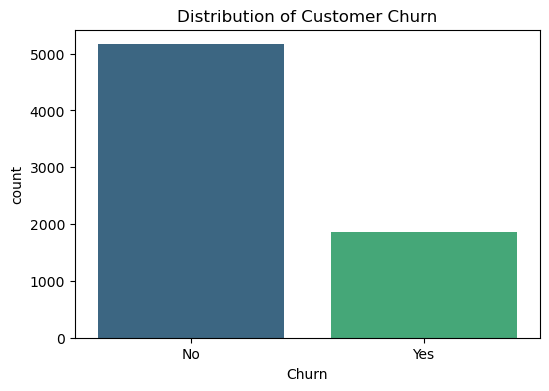

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='viridis')
plt.title('Distribution of Customer Churn')
plt.show()

# Check the percentage
print(df['Churn'].value_counts(normalize=True) * 100)


This shows that about one in four customers leave the company. Because the "Yes" group is smaller, we need to be very precise in identifying these specific individuals rather than just focusing on the majority who stay.

# 4. Numerical Features vs. Churn

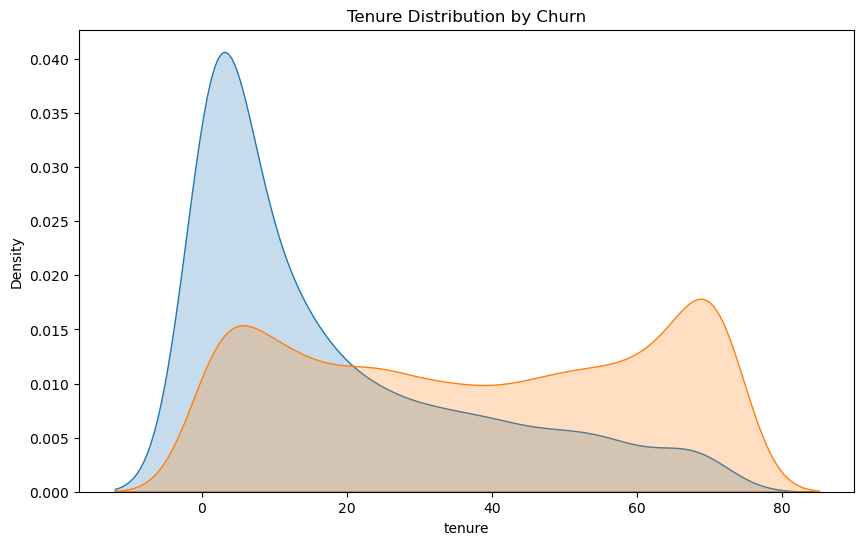

In [11]:
# How does tenure (loyalty) affect churn?
plt.figure(figsize=(10, 6))
sns.kdeplot(df[df['Churn'] == 'Yes']['tenure'], label='Churn: Yes', shade=True)
sns.kdeplot(df[df['Churn'] == 'No']['tenure'], label='Churn: No', shade=True)
plt.title('Tenure Distribution by Churn')
plt.show()

There is a large spike in people leaving during their very first few months of service. This makes the length of time a customer has been with us a major clue for spotting which accounts are at the highest risk of exiting.

# 5. Categorical Features (The "Why")

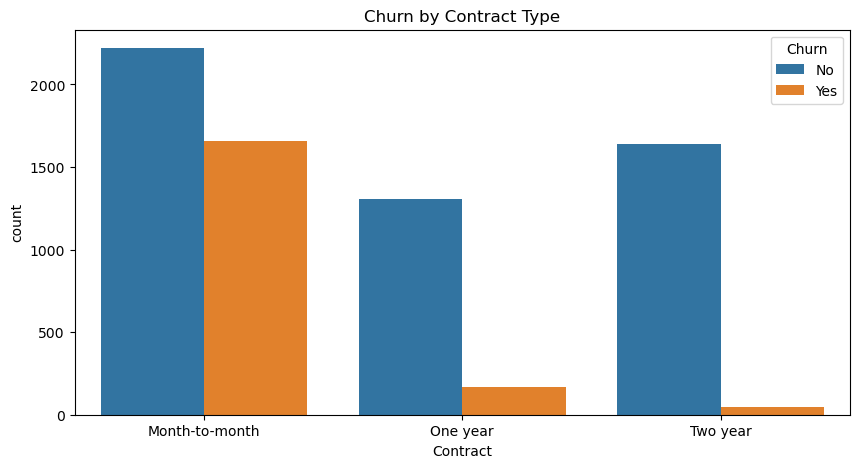

In [12]:
# Compare Churn across Contract types
plt.figure(figsize=(10, 5))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.show()

Customers on month-to-month plans leave at a much higher rate than those on one or two-year deals. This category acts as a strong signal to distinguish between loyal long-term customers and those who are likely to leave soon.

# 6. Feature Correlation

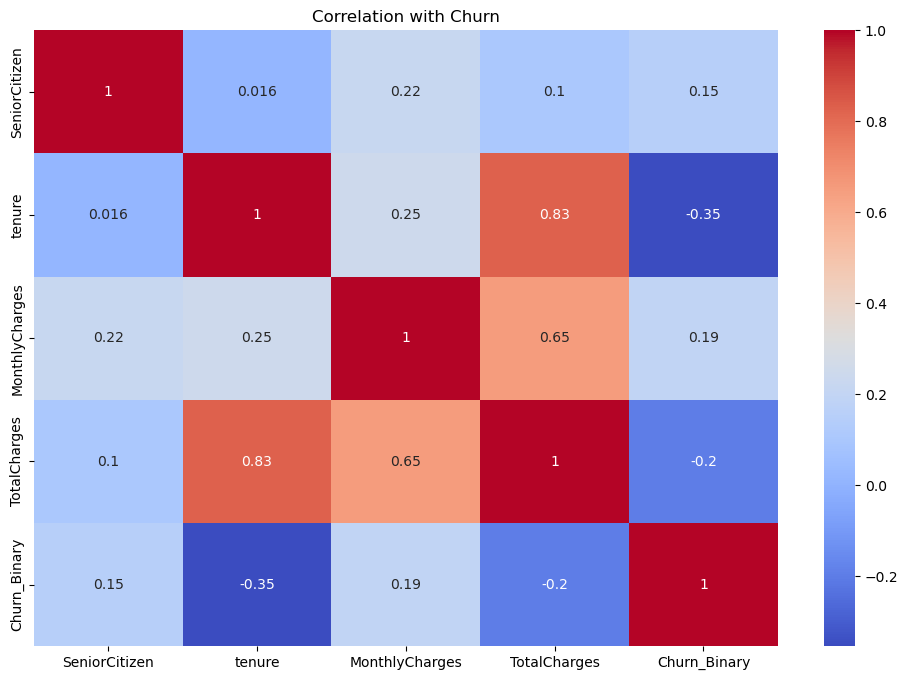

In [13]:
# Convert Churn to binary for correlation
df['Churn_Binary'] = df['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(12, 8))
# Correlate only numeric columns
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation with Churn')
plt.show()

We see that as monthly bills go up, the likelihood of a customer leaving also increases. Tracking these price points helps us understand which specific costs are causing the most people to walk away.

# 7. Advanced Visualization: The "Pairplot"

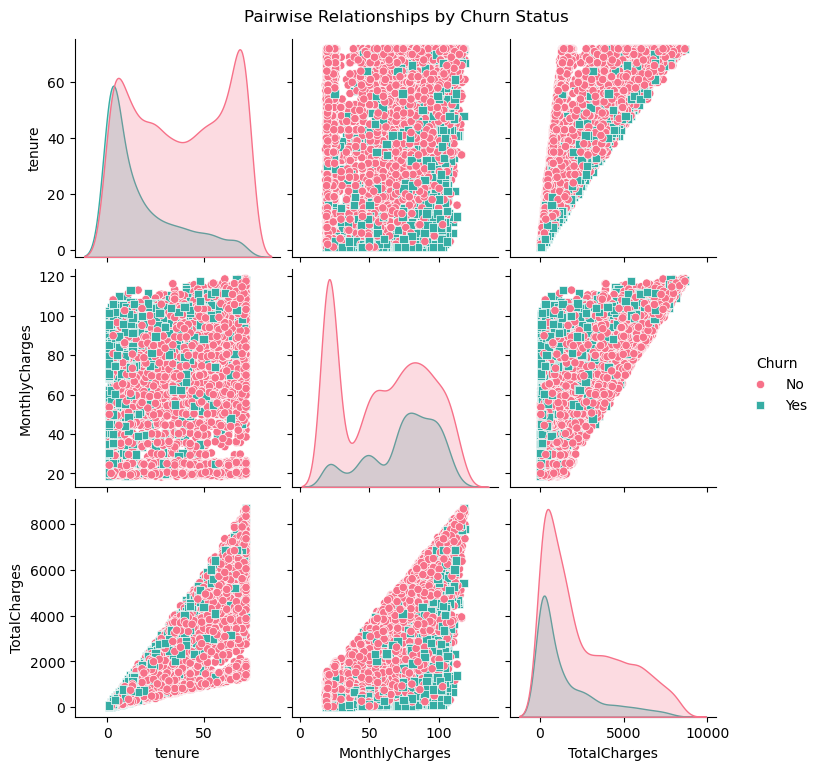

In [14]:
# Select key numerical features and the target
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']

# Pairplot to see clusters
sns.pairplot(df[numeric_cols], hue='Churn', palette='husl', markers=["o", "s"])
plt.suptitle('Pairwise Relationships by Churn Status', y=1.02)
plt.show()

The pairplot shows clear separation between churned and non-churned customers in the relationship between MonthlyCharges and Tenure. Specifically, a "danger zone" is visible in the top-left of the scatter plots where tenure is low but monthly costs are high, identifying a high-risk customer segment.

# 8. Feature Engineering: "The Ratio"

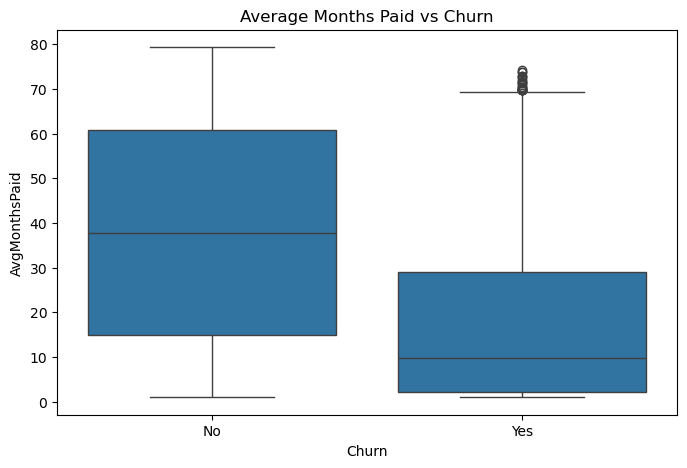

In [15]:
# Creating a feature that represents 'Average Months Paid'
df['AvgMonthsPaid'] = df['TotalCharges'] / df['MonthlyCharges']

# Compare this new feature against Churn
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='AvgMonthsPaid', data=df)
plt.title('Average Months Paid vs Churn')
plt.show()

This shows a significant gap between those who stay and those who leave. It provides a fresh way to separate the two groups based on how much they have actually invested relative to their monthly costs.

<Axes: xlabel='AvgMonthsPaid', ylabel='Count'>

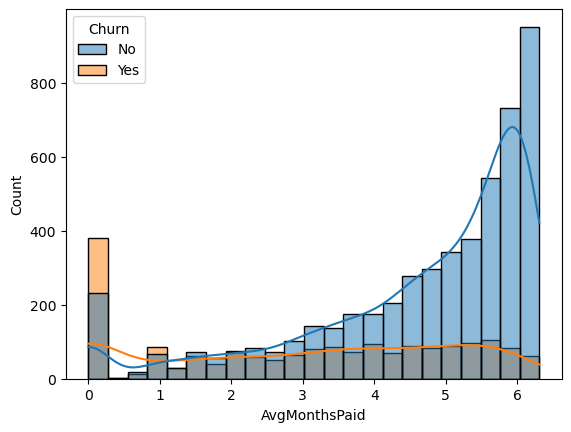

In [16]:
sns.histplot(hue='Churn', x=np.log2(df['AvgMonthsPaid']), data=df,kde=True)

# 9. Encoding Categorical Variables

In [17]:
# 1. Target
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 2. Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')
df = df.dropna()

# 3. Coding
df_final = pd.get_dummies(df, drop_first=True)

# 4. Checking
print(df_final.shape)
print(df_final.columns)


(7032, 33)
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'Churn_Binary', 'AvgMonthsPaid', 'gender_Male', 'Partner_Yes',
       'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No internet service',
       'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')


# 10. Final Correlation Check

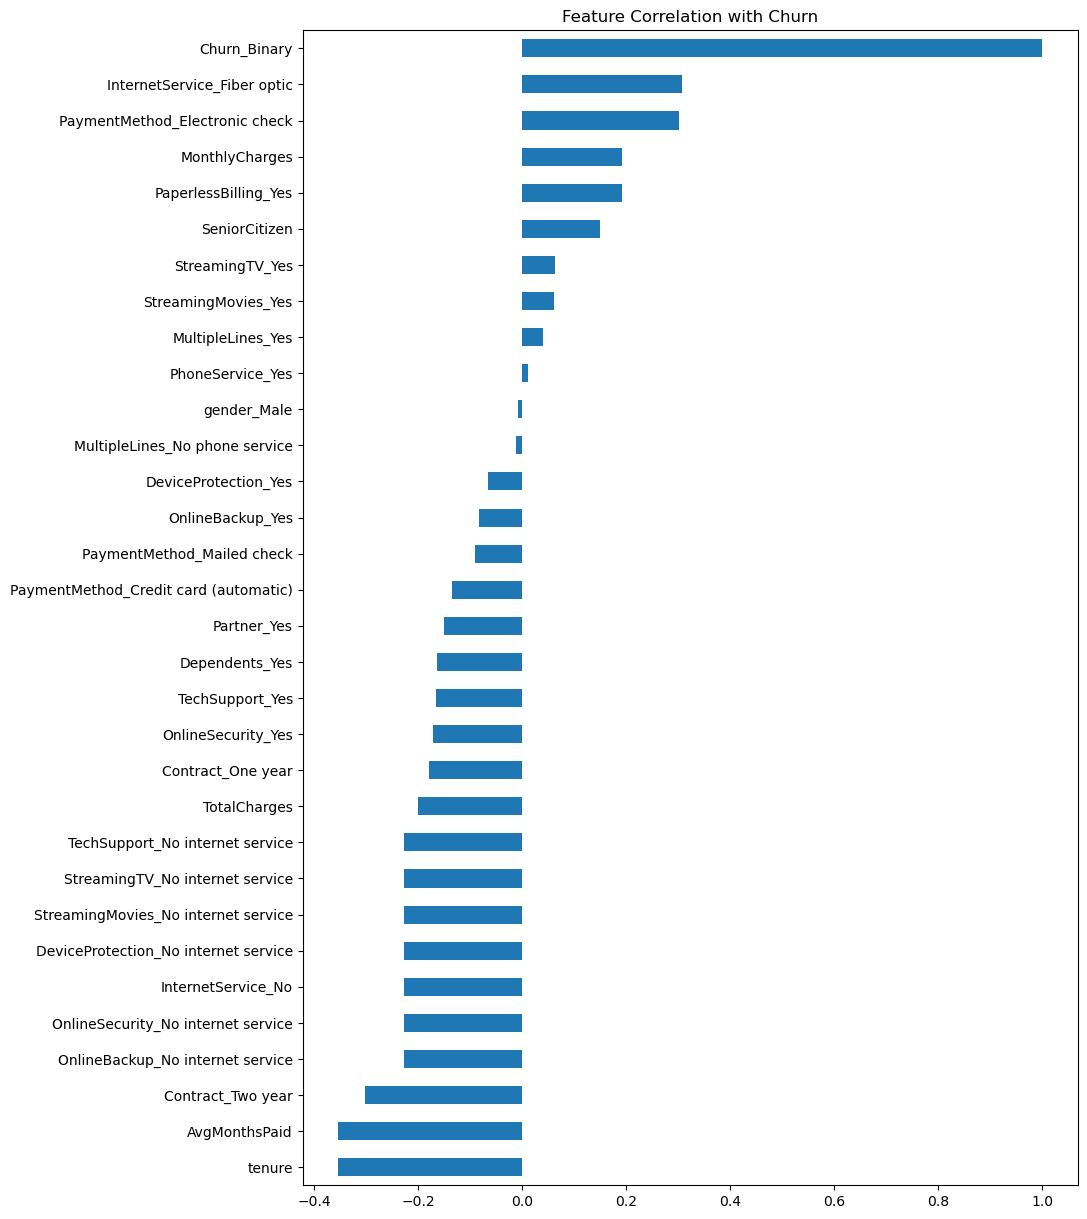

In [18]:
corr = df_final.corr()['Churn']

corr = corr.drop('Churn')

# Sorting
corr = corr.sort_values()

plt.figure(figsize=(10, 15))
corr.plot(kind='barh')
plt.title('Feature Correlation with Churn')
plt.show()

# 11. Scaling & Preprocessing & Train/Test Split


In [19]:
# Split X and y
X = df_final.drop('Churn', axis=1)
y = df_final['Churn']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

# Transform test
X_test = scaler.transform(X_test)

# Checking
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 32)
X_test shape: (1407, 32)
y_train shape: (5625,)
y_test shape: (1407,)


In [21]:
df_final.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,Churn_Binary,AvgMonthsPaid,gender_Male,Partner_Yes,Dependents_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1.000000,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,0,33.178227,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,1,2.008357,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,0,43.516548,True,False,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,1,2.144979,False,False,False,...,False,False,False,False,False,False,True,False,True,False
